# 06 — 3D U-Net: cross-validation

One U-Net per fold (seed 0), trained on 96³ patches for `N_ITERS` iterations (model and training loop in `src/unet.py`). The learning rate decreases from 1e-3 to 0 during training (polynomial decay, as in nnU-Net), so the end of training is stable and the model of the last iteration is kept.

Same as random forest, to understand how it works you can watch that : https://youtu.be/NhdzGfB1q74?si=95XoNvOvqLyoPdjQ

Every 250 iterations, the validation volumes of the fold are segmented with a sliding window over the whole volume and all the metrics are computed. These curves check that training has converged; they are not used to choose an iteration. As for the random forest, only the largest connected component of the prediction is kept. The test set is not used here.

Takes about 2 h on the RTX 4060 Laptop.

In [2]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

# shared functions of the project (src/unet.py and src/utils.py)
sys.path.insert(0, "../src")
from unet import segment, train
from utils import RESULTS, SPLITS, evaluate, fold_cases, load_case, normalize

N_ITERS = 5000  # training iterations (4 patches per iteration)
VAL_EVERY = 250  # validation every 250 iterations
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

# load the 15 development volumes once, with normalised intensities
data = {}
for c in SPLITS["dev"]:
    x, y, spacing = load_case(c)
    data[c] = (normalize(x), y, spacing)

## Training the 5 folds

In [3]:
rows = []
for k in range(len(SPLITS["folds"])):
    # 12 volumes to train, 3 volumes to evaluate
    train_cases, val_cases = fold_cases(k)

    # called by train() every VAL_EVERY iterations: segments the validation volumes and stores the metrics
    def validate(model, it):
        for c in val_cases:
            x, y, spacing = data[c]
            pred, _ = segment(model, x)
            rows.append({"fold": k, "iteration": it, "case": c, **evaluate(pred, y, spacing)})

    t0 = time.perf_counter()
    model = train([data[c][:2] for c in train_cases], N_ITERS, seed=0, callback=validate, every=VAL_EVERY)
    torch.save(model.state_dict(), MODEL_DIR / f"unet_cv_fold{k}.pt")
    # save after each fold so a crash does not lose everything
    pd.DataFrame(rows).to_csv(RESULTS / "cv_unet.csv", index=False)
    final_dice = pd.DataFrame(rows).query("fold == @k and iteration == @N_ITERS")["dice"].mean()
    print(f"fold {k}: {(time.perf_counter() - t0) / 60:.0f} min, final val Dice {final_dice:.3f}")

cv = pd.DataFrame(rows)

fold 0: 61 min, final val Dice 0.921
fold 1: 55 min, final val Dice 0.914
fold 2: 58 min, final val Dice 0.923
fold 3: 60 min, final val Dice 0.904
fold 4: 56 min, final val Dice 0.837


## Validation curves

mean val Dice at the end of training: 0.900


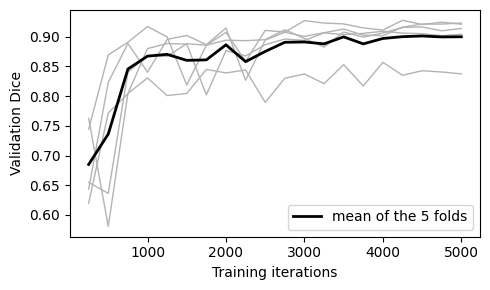

In [4]:
# mean validation Dice of each fold during training (one value every 250 iterations)
per_fold = cv.groupby(["iteration", "fold"])["dice"].mean().unstack()
mean_curve = per_fold.mean(axis=1)
print(f"mean val Dice at the end of training: {mean_curve.iloc[-1]:.3f}")

# grey: each fold, black: mean of the 5 folds
fig, ax = plt.subplots(figsize=(5, 3))
for k in per_fold.columns:
    ax.plot(per_fold.index, per_fold[k], color="0.7", lw=1)
ax.plot(mean_curve.index, mean_curve, color="k", lw=2, label="mean of the 5 folds")
ax.set_xlabel("Training iterations")
ax.set_ylabel("Validation Dice")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "fig_unet_cv_curve.png", dpi=300)
plt.show()

In [5]:
# cross-validation results of the final models (last iteration), for each volume
cols = ["dice", "hd95_mm", "sensitivity", "precision", "volume_error_ml"]
cv[cv["iteration"] == N_ITERS][["fold", "case"] + cols].round(3)

,fold,case,dice,hd95_mm,sensitivity,precision,volume_error_ml
57,0,la_003,0.941,2.236,0.933,0.949,-1.543
58,0,la_010,0.913,3.012,0.951,0.878,6.683
59,0,la_023,0.909,5.184,0.850,0.976,-11.988
136,1,la_005,0.918,4.296,0.892,0.946,-7.111
137,1,la_017,0.914,4.110,0.876,0.956,-6.713
138,1,la_022,0.903,5.274,0.949,0.862,7.282
139,1,la_026,0.919,4.184,0.928,0.910,2.192
197,2,la_007,0.918,3.750,0.865,0.977,-13.529
198,2,la_014,0.917,5.154,0.859,0.983,-18.377
199,2,la_024,0.934,2.851,0.938,0.929,0.963


In [6]:
# save the configuration (used by the final training notebook)
config_file = RESULTS / "chosen_configs.json"
configs = json.loads(config_file.read_text()) if config_file.exists() else {}
configs["unet"] = {"n_iters": N_ITERS}
config_file.write_text(json.dumps(configs, indent=2))

205